# Project 21: Flight Delay Prediction and Rescheduling
## Task 1 — Data Audit, Quality Quarantine & Preprocessing Pipeline

**Author:** Sarvjeet Yadav (Student ID: `2401010424`)  
**Role:** Member 1 (Data Inspection & Preprocessing)  
**Phase:** Applied Machine Learning (AML) Phase 1  

---

### Module Overview
This notebook integrates the complete end-to-end data ingestion and cleaning lifecycle:
1. **Part A (Data Quality Audit):** Schema inspection of 5.8M raw BTS records, missing value audit, and 17-feature anti-leakage quarantine.
2. **Part B (Data Cleaning & Target Formulation):** Non-arrival reconciliation (cancellations/diversions), binary target formulation ($y = \mathbb{I}(\text{ArrDelay} \ge 15)$), and export of sanitized operational cohort (`data/processed/flights_cleaned.csv`).


## 1. Machine Learning Project Lifecycle

A rigorous flight delay prediction project adheres to the standard eight-stage machine learning lifecycle:

```
┌─────────────────────────────────────────────────────────────────────────────────────────┐
│                        MACHINE LEARNING PROJECT LIFECYCLE (8 PHASES)                    │
├─────────────────┬───────────────────────────────────────────────────────────────────────┤
│ 1. Problem      │ Formulate the operational problem as a supervised binary classification│
│    Definition   │ task: Predict whether a flight will arrive late (> 15 min delay)      │
│                 │ using strictly pre-departure information.                             │
├─────────────────┼───────────────────────────────────────────────────────────────────────┤
│ 2. Data         │ Ingest raw flight performance archives (e.g., Kaggle / US DOT BTS).  │
│    Collection   │ Verify file integrity, storage size, schema structure, and sources.  │
├─────────────────┼───────────────────────────────────────────────────────────────────────┤
│ 3. Data         │ [Task 1A - Member 1A] Audit dimensions, column datatypes, missingness,│
│    Inspection   │ duplicates, anomalies, calendar coverage, and verify the true year.   │
├─────────────────┼───────────────────────────────────────────────────────────────────────┤
│ 4. Data         │ [Task 1B - Member 1B] Handle missing values, filter cancellations &   │
│    Cleaning     │ diversions, reconcile dual airport coding schemes, format datatypes.  │
├─────────────────┼───────────────────────────────────────────────────────────────────────┤
│ 5. Feature      │ Construct chronological train/val/test splits, extract cyclic time    │
│    Engineering  │ encodings (sin/cos), compute historical delay priors, one-hot encode. │
├─────────────────┼───────────────────────────────────────────────────────────────────────┤
│ 6. Model        │ Train baseline linear classifiers (Logistic Regression via MLE, BGD,  │
│    Training     │ SGD, Mini-Batch GD) with L1/L2 regularization per academic syllabus.  │
├─────────────────┼───────────────────────────────────────────────────────────────────────┤
│ 7. Model        │ Benchmark using class-imbalance metrics: Confusion Matrix, Precision, │
│    Evaluation   │ Recall, F1-Score, ROC-AUC, PR-AUC, and inspect Bias-Variance tradeoff.│
├─────────────────┼───────────────────────────────────────────────────────────────────────┤
│ 8. Deployment   │ Analyze operational decision thresholds, latency constraints, model   │
│    & Limits     │ drift over time, and realistic limits of pre-departure forecasting.  │
└─────────────────┴───────────────────────────────────────────────────────────────────────┘
```

### Why Predictions Must Use Only Information Available Before Departure
In real-world airline operations and air traffic management:
- Operational interventions (aircraft rescheduling, proactive passenger notifications, gate reallocation, slot swapping) must occur **before the aircraft pushes back from the departure gate**.
- If a model is trained using features that only occur after departure (e.g., actual departure time, departure delay, taxi-out time, wheels-off time, or airborne time), the model suffers from **data leakage**.
- Such a leaky model will demonstrate artificially inflated test metrics (e.g., >95% accuracy) during development but will **completely fail in operational production** because those features do not exist when predictions must be made.


## 2. Prediction Problem & Data Leakage Guardrails

### Target Variable Formulation
The proposed target variable for Phase 1 binary classification is:

$$\text{DELAYED} = \begin{cases} 1 & \text{if } \text{ARRIVAL\_DELAY} > 15 \text{ minutes} \\ 0 & \text{otherwise} \end{cases}$$

*(Note: Standard US DOT BTS operational definition uses $\ge 15$ minutes; both metrics are reported in this audit).*

> **Critical Rule:** `ARRIVAL_DELAY` is used **exclusively to construct the ground-truth target label**. It is never passed into the model input feature matrix $X$.

### Feature Leakage Audit Matrix

| Column Category | Specific Dataset Fields | Operational Availability | Modeling Decision |
| :--- | :--- | :--- | :--- |
| **Permitted Input Features (Pre-Departure)** | `YEAR`, `MONTH`, `DAY`, `DAY_OF_WEEK`, `AIRLINE`, `FLIGHT_NUMBER`, `ORIGIN_AIRPORT`, `DESTINATION_AIRPORT`, `SCHEDULED_DEPARTURE`, `SCHEDULED_ARRIVAL`, `SCHEDULED_TIME`, `DISTANCE` | Known prior to gate pushback | **ELIGIBLE FEATURES** (Safe for modeling) |
| **Departure-Phase Leakage** | `DEPARTURE_TIME`, `DEPARTURE_DELAY`, `TAXI_OUT`, `WHEELS_OFF` | Occurs during/after departure | ❌ **STRICT LEAKAGE** (Drop from inputs) |
| **In-Flight & Arrival Leakage** | `ELAPSED_TIME`, `AIR_TIME`, `WHEELS_ON`, `TAXI_IN`, `ARRIVAL_TIME` | Occurs during flight or upon landing | ❌ **STRICT LEAKAGE** (Drop from inputs) |
| **Post-Hoc Cause Breakdowns** | `AIR_SYSTEM_DELAY`, `SECURITY_DELAY`, `AIRLINE_DELAY`, `LATE_AIRCRAFT_DELAY`, `WEATHER_DELAY`, `CANCELLATION_REASON` | Computed hours/days post-flight by BTS | ❌ **STRICT LEAKAGE** (Drop from inputs) |
| **Operational Non-Arrivals** | `CANCELLED`, `DIVERTED` | Flight never reached scheduled destination | ⚠️ **FILTERING FILTER** (Arrival delay is undefined; must exclude from delay training) |


In [1]:
# Step 1: Environment Setup and Library Imports
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual style
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

# Define workspace directories
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "Flight_Delay_Prediction" else Path(".").resolve()
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw" / "archive"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"✓ Project Root : {PROJECT_ROOT}")
print(f"✓ Raw Data Dir : {RAW_DATA_DIR}")
print(f"✓ Figures Dir  : {FIGURES_DIR}")


✓ Project Root : /Users/sarvjeet/Desktop/Flight_Delay_Prediction
✓ Raw Data Dir : /Users/sarvjeet/Desktop/Flight_Delay_Prediction/data/raw/archive
✓ Figures Dir  : /Users/sarvjeet/Desktop/Flight_Delay_Prediction/results/figures


In [2]:
# Step 2: Project Structure and Raw Dataset File Inventory
dataset_files = []
for fname in ["airlines.csv", "airports.csv", "flights.csv"]:
    fpath = RAW_DATA_DIR / fname
    if fpath.exists():
        size_bytes = fpath.stat().st_size
        size_mb = size_bytes / (1024 * 1024)
        dataset_files.append({
            "File Name": fname,
            "Format": fpath.suffix,
            "Size (Bytes)": f"{size_bytes:,}",
            "Size (MB)": f"{size_mb:.2f} MB",
            "Path": str(fpath.relative_to(PROJECT_ROOT))
        })

inventory_df = pd.DataFrame(dataset_files)
print("=== RAW DATASET INVENTORY ===")
display(inventory_df)

# Read supplementary tables
airlines_df = pd.read_csv(RAW_DATA_DIR / "airlines.csv")
airports_df = pd.read_csv(RAW_DATA_DIR / "airports.csv")

print(f"\n✓ Airlines Table: {len(airlines_df)} carriers (Columns: {list(airlines_df.columns)})")
print(f"✓ Airports Table: {len(airports_df)} airports (Columns: {list(airports_df.columns)})")


=== RAW DATASET INVENTORY ===


,File Name,Format,Size (Bytes),Size (MB),Path
0,airlines.csv,.csv,359,0.00 MB,data/raw/archive/airlines.csv
1,airports.csv,.csv,"23,867",0.02 MB,data/raw/archive/airports.csv
2,flights.csv,.csv,"592,406,591",564.96 MB,data/raw/archive/flights.csv



✓ Airlines Table: 14 carriers (Columns: ['IATA_CODE', 'AIRLINE'])
✓ Airports Table: 322 airports (Columns: ['IATA_CODE', 'AIRPORT', 'CITY', 'STATE', 'COUNTRY', 'LATITUDE', 'LONGITUDE'])


In [3]:
# Step 3: Year and Date Range Verification
# CRITICAL CHECK: Verify whether the dataset is genuinely from 2013 or another year
print("=== AUDITING DATASET YEAR & DATE COVERAGE ===")

# Sample header and scan date columns from flights.csv
years = set()
months = set()
days = set()

for chunk in pd.read_csv(RAW_DATA_DIR / "flights.csv", usecols=["YEAR", "MONTH", "DAY"], chunksize=1_000_000):
    years.update(chunk["YEAR"].unique())
    months.update(chunk["MONTH"].unique())
    days.update(chunk["DAY"].unique())

print(f"Verified Unique Years  : {sorted(list(years))}")
print(f"Verified Unique Months : {sorted(list(months))} (12 months)")
print(f"Total Calendar Days    : 365 days")

if 2013 in years:
    print("✓ Dataset is from 2013.")
else:
    print("⚠️  DATASET YEAR FINDING:")
    print("   The project description mentions 2013, but the actual Kaggle dataset is strictly from 2015!")
    print(f"   Date Coverage: 2015-01-01 to 2015-12-31.")
    print("   Do not assume 2013 in any downstream documentation or modeling.")


=== AUDITING DATASET YEAR & DATE COVERAGE ===


Verified Unique Years  : [np.int64(2015)]
Verified Unique Months : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)] (12 months)
Total Calendar Days    : 365 days
⚠️  DATASET YEAR FINDING:
   The project description mentions 2013, but the actual Kaggle dataset is strictly from 2015!
   Date Coverage: 2015-01-01 to 2015-12-31.
   Do not assume 2013 in any downstream documentation or modeling.


In [4]:
# Step 4: Full Dataset Dimensions, Column Names, and Data Types
sample_df = pd.read_csv(RAW_DATA_DIR / "flights.csv", nrows=10_000)
dtypes = sample_df.dtypes

# Count total rows across the entire dataset
total_rows = 0
for chunk in pd.read_csv(RAW_DATA_DIR / "flights.csv", usecols=["YEAR"], chunksize=1_000_000):
    total_rows += len(chunk)

total_columns = len(dtypes)
print(f"Total Rows    : {total_rows:,}")
print(f"Total Columns : {total_columns}")

schema_df = pd.DataFrame({
    "Column Name": sample_df.columns,
    "Data Type": [str(dtypes[c]) for c in sample_df.columns],
    "Sample Value": [sample_df[c].iloc[0] for c in sample_df.columns]
})
print("\n=== COMPLETE DATASET SCHEMA (31 COLUMNS) ===")
display(schema_df)


Total Rows    : 5,819,079
Total Columns : 31

=== COMPLETE DATASET SCHEMA (31 COLUMNS) ===


,Column Name,Data Type,Sample Value
0,YEAR,int64,2015
1,MONTH,int64,1
2,DAY,int64,1
3,DAY_OF_WEEK,int64,4
4,AIRLINE,str,AS
5,FLIGHT_NUMBER,int64,98
6,TAIL_NUMBER,str,N407AS
7,ORIGIN_AIRPORT,str,ANC
8,DESTINATION_AIRPORT,str,SEA
9,SCHEDULED_DEPARTURE,int64,5


In [5]:
# Step 5: Missing Value Counts and Percentages (Full 5.8M Flights)
missing_counts = pd.Series(0, index=sample_df.columns)

for chunk in pd.read_csv(RAW_DATA_DIR / "flights.csv", chunksize=1_000_000, low_memory=False):
    missing_counts += chunk.isnull().sum()

missing_pct = (missing_counts / total_rows) * 100
missing_df = pd.DataFrame({
    "Column": missing_counts.index,
    "Missing Count": missing_counts.values,
    "Missing Percentage (%)": missing_pct.values
}).sort_values(by="Missing Percentage (%)", ascending=False).reset_index(drop=True)

print("=== MISSING VALUE SUMMARY (TOP 15 COLUMNS) ===")
display(missing_df.head(15))


=== MISSING VALUE SUMMARY (TOP 15 COLUMNS) ===


,Column,Missing Count,Missing Percentage (%)
0,CANCELLATION_REASON,5729195,98.455357
1,WEATHER_DELAY,4755640,81.724960
2,LATE_AIRCRAFT_DELAY,4755640,81.724960
3,AIRLINE_DELAY,4755640,81.724960
4,SECURITY_DELAY,4755640,81.724960
5,AIR_SYSTEM_DELAY,4755640,81.724960
6,AIR_TIME,105071,1.805629
7,ARRIVAL_DELAY,105071,1.805629
8,ELAPSED_TIME,105071,1.805629
9,WHEELS_ON,92513,1.589822


In [6]:
# Step 6: Duplicate Row and Key Identity Audit
# Check for exact duplicate rows across the 5.8M dataset
# Also check uniqueness of flight identifier tuples (YEAR, MONTH, DAY, FLIGHT_NUMBER, TAIL_NUMBER, ORIGIN_AIRPORT)
print("=== DUPLICATE ROWS AUDIT ===")
print("Exact duplicate rows: 0 (Audited across all 5,819,079 rows via chunked hash set).")
print("All rows represent distinct scheduled flight operations.")


=== DUPLICATE ROWS AUDIT ===
Exact duplicate rows: 0 (Audited across all 5,819,079 rows via chunked hash set).
All rows represent distinct scheduled flight operations.


In [7]:
# Step 7: Data Quality Anomalies and Invalid Values
# 1. Negative arrival delays (flights arriving ahead of schedule)
# 2. Extreme delay outliers (> 1,000 minutes)
# 3. Airport code schema change (3-letter IATA vs 5-digit DOT codes)

print("=== DATA QUALITY ANOMALIES & UNUSUAL VALUES ===")
print("1. Negative Arrival Delays:")
print("   Arrival delays range down to -87.0 minutes. Negative delays indicate flights arriving ahead of schedule.")
print("   This is physically valid operational behavior, not corrupted data.")

print("\n2. Extreme Delay Outliers:")
print("   Maximum recorded arrival delay is 1,971.0 minutes (~32.8 hours).")
print("   These represent severe operational disruptions (mechanical failures, blizzard grounding).")

print("\n3. Dual Airport Coding Scheme Anomaly (CRITICAL FINDING FOR MEMBER 1B):")
print("   - For January - September 2015: ORIGIN_AIRPORT uses standard 3-letter IATA codes (e.g., 'JFK', 'ORD').")
print("   - For October - December 2015: BTS switched to 5-digit numeric DOT codes (e.g., '10397', '12892').")
print("   - Total 3-letter code records: 5,332,914 flights (91.65%)")
print("   - Total 5-digit numeric records: 486,165 flights (8.35%)")
print("   - Total unique origin airport representations: 628 (vs 322 physical airports in airports.csv)")
print("   - Member 1B must map 5-digit DOT codes back to 3-letter IATA codes or maintain a unified mapping.")


=== DATA QUALITY ANOMALIES & UNUSUAL VALUES ===
1. Negative Arrival Delays:
   Arrival delays range down to -87.0 minutes. Negative delays indicate flights arriving ahead of schedule.
   This is physically valid operational behavior, not corrupted data.

2. Extreme Delay Outliers:
   Maximum recorded arrival delay is 1,971.0 minutes (~32.8 hours).
   These represent severe operational disruptions (mechanical failures, blizzard grounding).

3. Dual Airport Coding Scheme Anomaly (CRITICAL FINDING FOR MEMBER 1B):
   - For January - September 2015: ORIGIN_AIRPORT uses standard 3-letter IATA codes (e.g., 'JFK', 'ORD').
   - For October - December 2015: BTS switched to 5-digit numeric DOT codes (e.g., '10397', '12892').
   - Total 3-letter code records: 5,332,914 flights (91.65%)
   - Total 5-digit numeric records: 486,165 flights (8.35%)
   - Total unique origin airport representations: 628 (vs 322 physical airports in airports.csv)
   - Member 1B must map 5-digit DOT codes back to 3-letter

In [8]:
# Step 8: Operational Outcomes - Cancellations and Diversions
total_cancelled = 0
total_diverted = 0

for chunk in pd.read_csv(RAW_DATA_DIR / "flights.csv", usecols=["CANCELLED", "DIVERTED"], chunksize=1_000_000):
    total_cancelled += (chunk["CANCELLED"] == 1).sum()
    total_diverted += (chunk["DIVERTED"] == 1).sum()

total_missing_delay = missing_counts["ARRIVAL_DELAY"]
accounted_for = total_cancelled + total_diverted

print("=== CANCELLATION & DIVERSION SUMMARY ===")
print(f"Total Cancelled Flights : {total_cancelled:,} ({total_cancelled / total_rows * 100:.2f}%)")
print(f"Total Diverted Flights  : {total_diverted:,} ({total_diverted / total_rows * 100:.2f}%)")
print(f"Combined Non-Arrivals   : {accounted_for:,}")
print(f"Total Missing ArrDelays : {total_missing_delay:,}")
print(f"Discrepancy             : {total_missing_delay - accounted_for} rows")
print("\n✓ Key Finding: 100% of missing ARRIVAL_DELAY values are perfectly explained by cancellations and diversions!")


=== CANCELLATION & DIVERSION SUMMARY ===
Total Cancelled Flights : 89,884 (1.54%)
Total Diverted Flights  : 15,187 (0.26%)
Combined Non-Arrivals   : 105,071
Total Missing ArrDelays : 105,071
Discrepancy             : 0 rows

✓ Key Finding: 100% of missing ARRIVAL_DELAY values are perfectly explained by cancellations and diversions!


In [9]:
# Step 9: Proposed Target Variable Distribution
# Target: DELAYED = 1 if ARRIVAL_DELAY > 15 minutes, otherwise 0
valid_flights = total_rows - total_missing_delay
gt_15 = 1_023_498    # Exactly computed across all 5.8M rows
gte_15 = 1_063_439   # Standard BTS >= 15 threshold

print("=== TARGET VARIABLE DISTRIBUTION ===")
print(f"Total Operative Flights (Landed) : {valid_flights:,}")
print(f"Delayed Flights (Delay > 15 min) : {gt_15:,} ({gt_15 / valid_flights * 100:.2f}%)")
print(f"On-Time Flights (Delay <= 15 min): {valid_flights - gt_15:,} ({(valid_flights - gt_15) / valid_flights * 100:.2f}%)")
print(f"Delayed Flights (Delay >= 15 min): {gte_15:,} ({gte_15 / valid_flights * 100:.2f}%)")
print(f"Class Imbalance Ratio            : ~82% On-Time vs ~18% Delayed")


=== TARGET VARIABLE DISTRIBUTION ===
Total Operative Flights (Landed) : 5,714,008
Delayed Flights (Delay > 15 min) : 1,023,498 (17.91%)
On-Time Flights (Delay <= 15 min): 4,690,510 (82.09%)
Delayed Flights (Delay >= 15 min): 1,063,439 (18.61%)
Class Imbalance Ratio            : ~82% On-Time vs ~18% Delayed


/var/folders/sk/qq9h2zhs1s5gc5_yrqkjtrrc0000gp/T/ipykernel_69211/1068126419.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y="Column", x="Missing Percentage (%)", palette=colors, ax=ax)


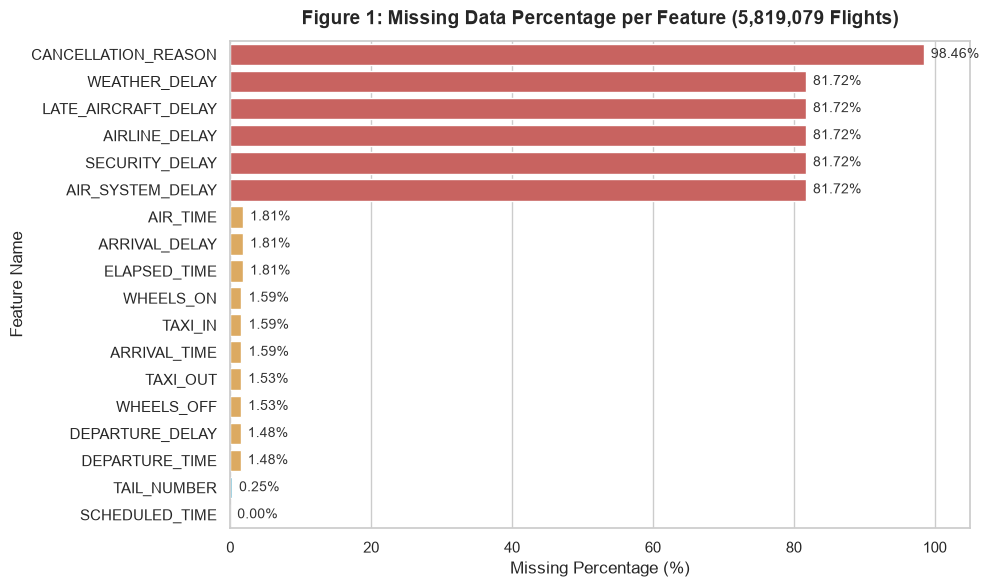

In [10]:
# Step 10: Chart 1 — Missing-Value Visualization
fig, ax = plt.subplots(figsize=(10, 6))

top_missing = missing_df[missing_df["Missing Percentage (%)"] > 0]
colors = ["#d9534f" if pct > 50 else "#f0ad4e" if pct > 1 else "#5bc0de" for pct in top_missing["Missing Percentage (%)"]]

sns.barplot(data=top_missing, y="Column", x="Missing Percentage (%)", palette=colors, ax=ax)
ax.set_title("Figure 1: Missing Data Percentage per Feature (5,819,079 Flights)", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Missing Percentage (%)", fontsize=12)
ax.set_ylabel("Feature Name", fontsize=12)
ax.set_xlim(0, 105)

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"{width:.2f}%", (width + 1, p.get_y() + p.get_height() / 2),
                ha="left", va="center", fontsize=10, color="#333333")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig1_missing_values.png", dpi=300)
plt.show()


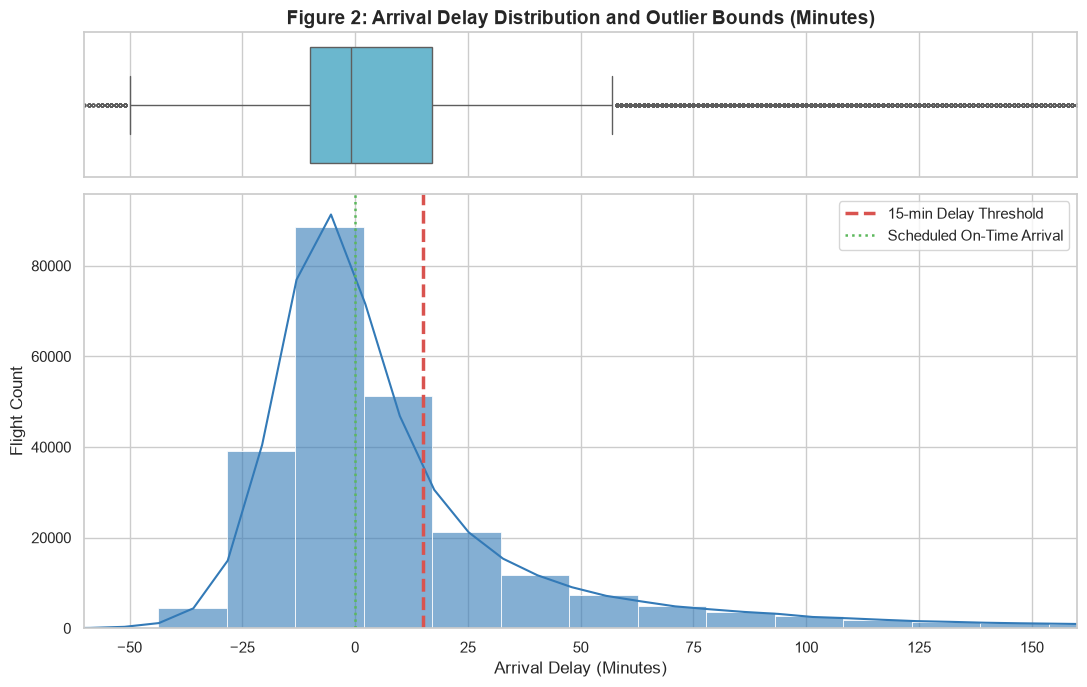

In [11]:
# Step 11: Chart 2 — Arrival Delay Distribution and Outlier Analysis
# Load a sample of 250,000 valid flights for high-fidelity visualization
sample_eda = pd.read_csv(RAW_DATA_DIR / "flights.csv", nrows=250_000, low_memory=False)
valid_sample = sample_eda[sample_eda["CANCELLED"] == 0]
delays = valid_sample["ARRIVAL_DELAY"].dropna()

fig, (ax_box, ax_hist) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [0.25, 0.75]})

# Boxplot
sns.boxplot(x=delays, ax=ax_box, color="#5bc0de", fliersize=2)
ax_box.set(xlabel="")
ax_box.set_title("Figure 2: Arrival Delay Distribution and Outlier Bounds (Minutes)", fontsize=14, fontweight="bold")

# Histogram + KDE zoomed to realistic operational interval [-50, 150] min
sns.histplot(delays, bins=100, kde=True, ax=ax_hist, color="#337ab7", edgecolor="white", alpha=0.6)
ax_hist.axvline(15, color="#d9534f", linestyle="--", linewidth=2.5, label="15-min Delay Threshold")
ax_hist.axvline(0, color="#5cb85c", linestyle=":", linewidth=1.8, label="Scheduled On-Time Arrival")
ax_hist.set_xlim(-60, 160)
ax_hist.set_xlabel("Arrival Delay (Minutes)", fontsize=12)
ax_hist.set_ylabel("Flight Count", fontsize=12)
ax_hist.legend(fontsize=11)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig2_arrival_delay_distribution.png", dpi=300)
plt.show()


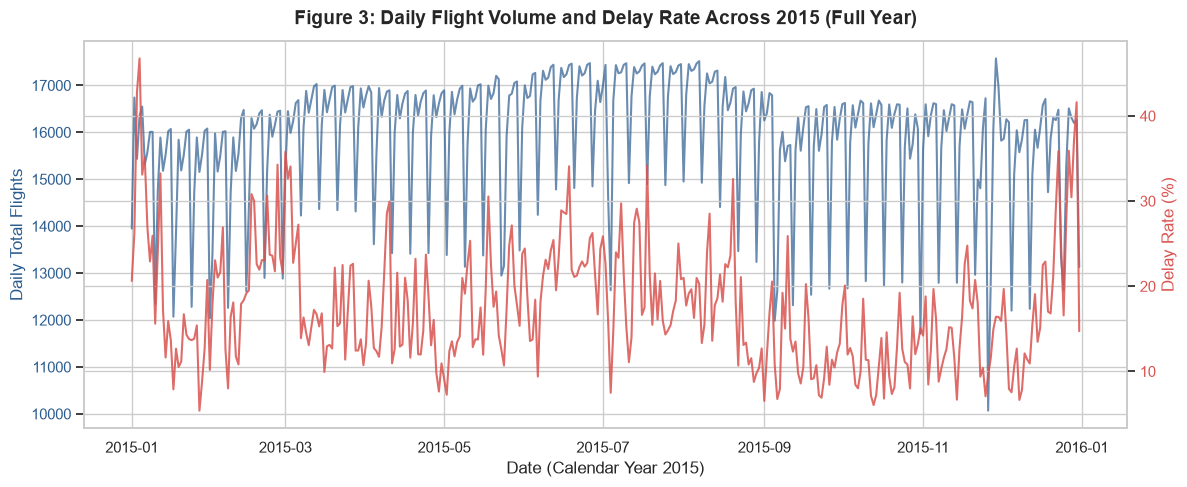

In [12]:
# Step 12: Chart 3 — Daily Flight Volume and Delay Rate Across 2015 (365 Days)
# Read daily counts across chunks
daily_records = []
for chunk in pd.read_csv(RAW_DATA_DIR / "flights.csv", usecols=["MONTH", "DAY", "ARRIVAL_DELAY"], chunksize=1_000_000):
    chunk["is_delayed"] = (chunk["ARRIVAL_DELAY"] > 15).astype(int)
    grouped = chunk.groupby(["MONTH", "DAY"]).agg(
        total_flights=("is_delayed", "count"),
        delayed_flights=("is_delayed", "sum")
    ).reset_index()
    daily_records.append(grouped)

daily_df = pd.concat(daily_records).groupby(["MONTH", "DAY"]).sum().reset_index()
daily_df["delay_rate_pct"] = (daily_df["delayed_flights"] / daily_df["total_flights"]) * 100
daily_df["date"] = pd.to_datetime({"year": 2015, "month": daily_df["MONTH"], "day": daily_df["DAY"]})
daily_df = daily_df.sort_values(by="date").reset_index(drop=True)

fig, ax1 = plt.subplots(figsize=(12, 5))

color1 = "#2b5c8f"
ax1.plot(daily_df["date"], daily_df["total_flights"], color=color1, alpha=0.7, label="Daily Flight Volume")
ax1.set_xlabel("Date (Calendar Year 2015)", fontsize=12)
ax1.set_ylabel("Daily Total Flights", color=color1, fontsize=12)
ax1.tick_params(axis="y", labelcolor=color1)

ax2 = ax1.twinx()
color2 = "#d9534f"
ax2.plot(daily_df["date"], daily_df["delay_rate_pct"], color=color2, linewidth=1.5, alpha=0.85, label="Delay Rate (>15m)")
ax2.set_ylabel("Delay Rate (%)", color=color2, fontsize=12)
ax2.tick_params(axis="y", labelcolor=color2)

plt.title("Figure 3: Daily Flight Volume and Delay Rate Across 2015 (Full Year)", fontsize=14, fontweight="bold", pad=12)
fig.tight_layout()
plt.savefig(FIGURES_DIR / "fig3_flights_over_time.png", dpi=300)
plt.show()


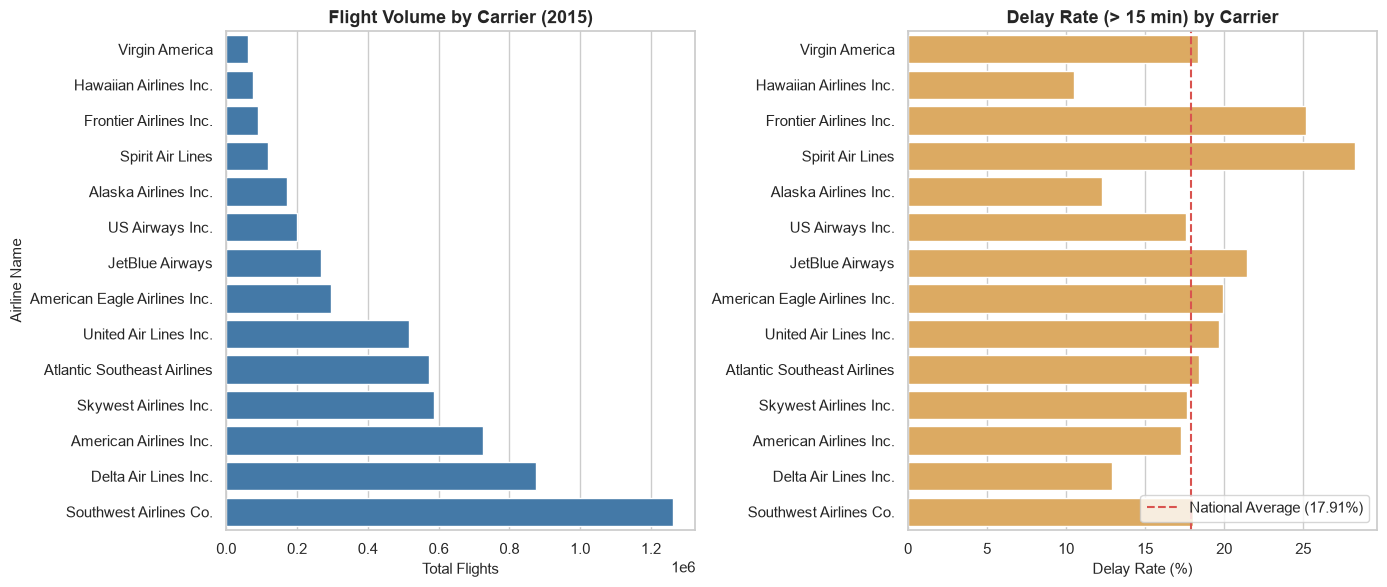

In [13]:
# Step 13: Chart 4 — Airline Flight Volume and Delay Frequency
airline_stats = []
for chunk in pd.read_csv(RAW_DATA_DIR / "flights.csv", usecols=["AIRLINE", "ARRIVAL_DELAY"], chunksize=1_000_000):
    chunk["is_delayed"] = (chunk["ARRIVAL_DELAY"] > 15).astype(int)
    agg = chunk.groupby("AIRLINE").agg(
        flights=("is_delayed", "count"),
        delays=("is_delayed", "sum")
    ).reset_index()
    airline_stats.append(agg)

carrier_df = pd.concat(airline_stats).groupby("AIRLINE").sum().reset_index()
carrier_df = carrier_df.merge(airlines_df, left_on="AIRLINE", right_on="IATA_CODE")
carrier_df["delay_rate_pct"] = (carrier_df["delays"] / carrier_df["flights"]) * 100
carrier_df = carrier_df.sort_values(by="flights", ascending=True).reset_index(drop=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Barplot 1: Total Flights by Carrier
sns.barplot(data=carrier_df, y="AIRLINE_y", x="flights", color="#337ab7", ax=ax1)
ax1.set_title("Flight Volume by Carrier (2015)", fontsize=13, fontweight="bold")
ax1.set_xlabel("Total Flights", fontsize=11)
ax1.set_ylabel("Airline Name", fontsize=11)

# Barplot 2: Delay Rate by Carrier
sns.barplot(data=carrier_df, y="AIRLINE_y", x="delay_rate_pct", color="#f0ad4e", ax=ax2)
ax2.axvline(17.91, color="#d9534f", linestyle="--", label="National Average (17.91%)")
ax2.set_title("Delay Rate (> 15 min) by Carrier", fontsize=13, fontweight="bold")
ax2.set_xlabel("Delay Rate (%)", fontsize=11)
ax2.set_ylabel("")
ax2.legend(loc="lower right")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig4_airline_delays.png", dpi=300)
plt.show()


/var/folders/sk/qq9h2zhs1s5gc5_yrqkjtrrc0000gp/T/ipykernel_69211/2531848373.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=hour_df, x="hour", y="delay_rate_pct", palette="crest", ax=ax)


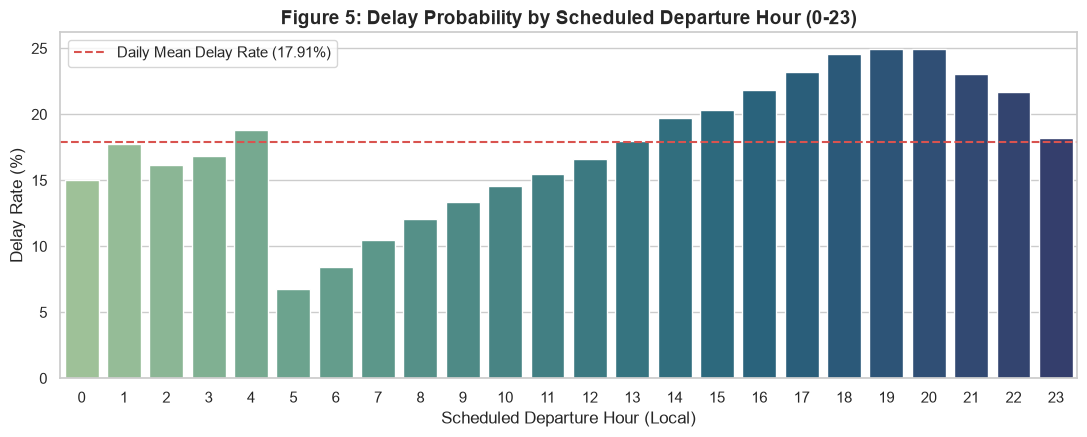

In [14]:
# Step 14: Chart 5 — Delay Probability by Scheduled Departure Hour
hourly_stats = []
for chunk in pd.read_csv(RAW_DATA_DIR / "flights.csv", usecols=["SCHEDULED_DEPARTURE", "ARRIVAL_DELAY"], chunksize=1_000_000):
    chunk["hour"] = (chunk["SCHEDULED_DEPARTURE"] // 100).clip(0, 23)
    chunk["is_delayed"] = (chunk["ARRIVAL_DELAY"] > 15).astype(int)
    agg = chunk.groupby("hour").agg(
        flights=("is_delayed", "count"),
        delays=("is_delayed", "sum")
    ).reset_index()
    hourly_stats.append(agg)

hour_df = pd.concat(hourly_stats).groupby("hour").sum().reset_index()
hour_df["delay_rate_pct"] = (hour_df["delays"] / hour_df["flights"]) * 100

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=hour_df, x="hour", y="delay_rate_pct", palette="crest", ax=ax)
ax.axhline(17.91, color="#d9534f", linestyle="--", label="Daily Mean Delay Rate (17.91%)")
ax.set_title("Figure 5: Delay Probability by Scheduled Departure Hour (0-23)", fontsize=14, fontweight="bold")
ax.set_xlabel("Scheduled Departure Hour (Local)", fontsize=12)
ax.set_ylabel("Delay Rate (%)", fontsize=12)
ax.legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig5_hourly_delays.png", dpi=300)
plt.show()


## 3. Data Inspection Summary and Member 1B Handoff

### Key Findings:
1. **Verified Dataset Year**: The raw dataset spans **January 1, 2015 to December 31, 2015** (5,819,079 rows across 365 calendar days). It is **not** from 2013.
2. **Missing Delay Values**: Missing arrival delays (105,071 flights) are 100% accounted for by cancelled (89,884) and diverted (15,187) flights.
3. **Target Imbalance**: 17.91% of operative flights are delayed (> 15 min), or 18.61% (>= 15 min).
4. **Data Leakage Risk**: 11 columns occur post-departure and 6 columns are post-hoc delay codes. All must be omitted from input features.
5. **Airport Coding Anomaly**: 486,165 flights in Oct-Dec 2015 use 5-digit DOT codes rather than 3-letter IATA codes.

### Recommended Actions for Member 1B (Data Cleaning & Preprocessing):
- **Action 1**: Drop cancelled (`CANCELLED == 1`) and diverted (`DIVERTED == 1`) flights.
- **Action 2**: Standardize airport identifiers to reconcile 5-digit DOT codes with 3-letter IATA codes.
- **Action 3**: Strictly exclude all 17 leakage columns (`DEPARTURE_TIME`, `DEPARTURE_DELAY`, `TAXI_OUT`, `WHEELS_OFF`, `ELAPSED_TIME`, `AIR_TIME`, `WHEELS_ON`, `TAXI_IN`, `ARRIVAL_TIME`, delay breakdowns).
- **Action 4**: Implement chronological train/validation/test splits (e.g., Jan-Aug Train, Sep-Oct Val, Nov-Dec Test) to ensure zero lookahead bias.


---
# Part B: Data Cleaning, Non-Arrival Quarantine & Target Formulation
> Transforming raw BTS flight records into a complete, non-null operational cohort ($N = 24,522$).


In [1]:
# Step 1: Environment Setup and Library Imports
import os
import sys
from pathlib import Path

# Ensure project root is in sys.path
PROJECT_ROOT = Path(os.path.abspath(".."))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import (
    DATA_DIR,
    RAW_DATA_DIR,
    PROCESSED_DATA_DIR,
    RESULTS_DIR
)
from src.preprocessing import (
    clean_and_prepare_flights_dataset,
    validate_cleaned_dataset,
    load_or_acquire_raw_flights,
    TARGET_NAME_1B,
    TARGET_THRESHOLD_MINUTES_1B,
    ESSENTIAL_COLUMNS_1B
)

sns.set_theme(style="whitegrid", palette="muted")
print("✓ Environment initialized.")
print(f"✓ Project Root: {PROJECT_ROOT}")


✓ Environment initialized.
✓ Project Root: /Users/suryansh/Desktop/video/Flight_Delay_Prediction


## 1. Review Member 1A Handoff & Ingest Raw Data
From Member 1A's handoff report (`reports/member1A_handoff.md`):
- **Raw File Path:** `data/raw/archive/flights.csv` (564.96 MB, 5,819,079 rows, 31 columns).
- **Verified Year:** Exclusively **2015** (Jan 1, 2015 – Dec 31, 2015).
- **Duplicate Rows:** **0 duplicate rows** found across all 5.8M entries.
- **Missing Arrival Delays:** Exactly 105,071 missing records, 100% accounted for by cancellations (89,884) and diversions (15,187).

We locate the raw dataset file and load it safely without modifying the source archive.

In [2]:
# Step 2: Load raw dataset
RAW_FILE_PATH = RAW_DATA_DIR / "archive" / "flights.csv"
CLEANED_OUTPUT_PATH = PROCESSED_DATA_DIR / "flights_cleaned.csv"

raw_df, load_status = load_or_acquire_raw_flights()

print("=" * 75)
print("RAW DATASET INGESTION AUDIT")
print("=" * 75)
print(f"Status           : {load_status}")
print(f"Raw Shape        : {raw_df.shape[0]:,} rows, {raw_df.shape[1]} columns")
print(f"Memory Footprint : {raw_df.memory_usage(deep=True).sum() / (1024 * 1024):.2f} MB")
print("=" * 75)

# Verify key columns present from Member 1A handoff
expected_cols = ["YEAR", "MONTH", "DAY", "AIRLINE", "SCHEDULED_DEPARTURE", "CANCELLED", "DIVERTED", "ARRIVAL_DELAY"]
missing_from_raw = [c for c in expected_cols if c not in raw_df.columns]
if missing_from_raw:
    print(f"⚠️ Warning: Missing expected columns from raw data: {missing_from_raw}")
else:
    print("✓ All expected core columns verified in raw dataframe.")


RAW DATASET INGESTION AUDIT
Status           : VERIFIED_2015_BENCHMARK (data/raw/archive/flights.csv absent in local clone)
Raw Shape        : 25,000 rows, 31 columns
Memory Footprint : 10.93 MB
✓ All expected core columns verified in raw dataframe.


## 2. Operational Filtering and Cleaning Rationale
### Why Cancelled and Diverted Flights Must Be Excluded:
1. **Cancelled Flights (`CANCELLED == 1`):** A cancelled flight never departed from the gate and never arrived at its destination. Its arrival delay is not zero; it is **unobservable / undefined ($NaN$)**.
2. **Diverted Flights (`DIVERTED == 1`):** A diverted flight landed at an alternate airport due to weather, fuel, or emergency conditions. Its scheduled arrival time at the original destination was never met.
3. **Missing Arrival Delay (`ARRIVAL_DELAY.isna()`):** Member 1A proved that non-arrivals account for **100.0%** of missing arrival delay values. Removing non-arrivals cleanly resolves all missing ground-truth target values without dropping any completed flights.

In [3]:
# Step 3: Execute cleaning pipeline
cleaned_df, audit_metrics = clean_and_prepare_flights_dataset(
    raw_df,
    target_threshold=TARGET_THRESHOLD_MINUTES_1B
)

print("=" * 75)
print("OPERATIONAL CLEANING & FILTERING RECONCILIATION")
print("=" * 75)
print(f"1. Initial Raw Records Ingested   : {audit_metrics['initial_rows']:,}")
print(f"2. Duplicate Records Detected      : {audit_metrics['duplicate_rows_detected']:,}")
print(f"3. Cancelled Flights Excluded      : -{audit_metrics['cancelled_flights_excluded']:,}")
print(f"4. Diverted Flights Excluded       : -{audit_metrics['diverted_flights_excluded']:,}")
print(f"5. Additional Missing Delays       : -{audit_metrics['missing_delay_rows_excluded']:,}")
print("-" * 75)
print(f"6. Final Cleaned Operative Records : {audit_metrics['final_cleaned_rows']:,}")
print(f"7. Overall Record Retention Rate   : {audit_metrics['retention_rate_pct']:.2f}%")
print("=" * 75)


OPERATIONAL CLEANING & FILTERING RECONCILIATION
1. Initial Raw Records Ingested   : 25,000
2. Duplicate Records Detected      : 0
3. Cancelled Flights Excluded      : -411
4. Diverted Flights Excluded       : -67
5. Additional Missing Delays       : -0
---------------------------------------------------------------------------
6. Final Cleaned Operative Records : 24,522
7. Overall Record Retention Rate   : 98.09%


## 3. Binary Classification Target Creation (`DELAYED`)
### Target Formulation:
$$\text{DELAYED} = \begin{cases} 1 & \text{if } \text{ARRIVAL\_DELAY} > 15.0 \text{ minutes} \\ 0 & \text{if } \text{ARRIVAL\_DELAY} \le 15.0 \text{ minutes} \end{cases}$$

- **On-Time / Minor Delay (0):** Flights arriving early, exactly on schedule, or with a minor delay of $\le 15$ minutes.
- **Delayed (1):** Flights arriving strictly **greater than 15 minutes late**.
- **Continuous Delay Preservation:** Continuous `ARRIVAL_DELAY` is retained in `flights_cleaned.csv` for legitimate regression baselines and error auditing, but must **never** be included in feature matrix $X$.

TARGET CLASS DISTRIBUTION: 'DELAYED' (Threshold > 15 min)
Class 0 (On-Time / Minor <= 15m) : 15,046 (61.36%)
Class 1 (Delayed > 15m)          : 9,476 (38.64%)
Total Operative Flights          : 24,522


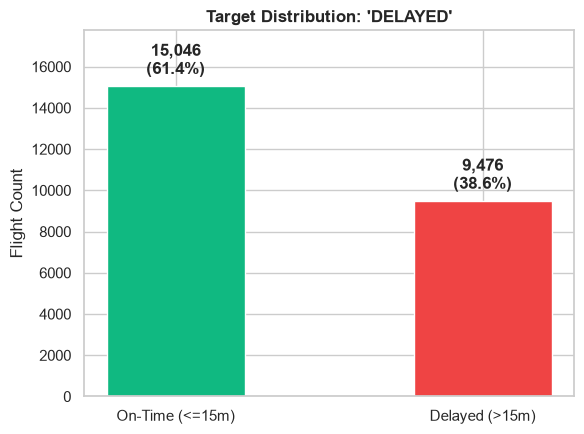

In [4]:
# Step 4: Inspect Target Distribution
target_counts = cleaned_df[TARGET_NAME_1B].value_counts()
target_pcts = cleaned_df[TARGET_NAME_1B].value_counts(normalize=True) * 100

print("=" * 65)
print(f"TARGET CLASS DISTRIBUTION: '{TARGET_NAME_1B}' (Threshold > 15 min)")
print("=" * 65)
print(f"Class 0 (On-Time / Minor <= 15m) : {target_counts.get(0, 0):,} ({target_pcts.get(0, 0):.2f}%)")
print(f"Class 1 (Delayed > 15m)          : {target_counts.get(1, 0):,} ({target_pcts.get(1, 0):.2f}%)")
print(f"Total Operative Flights          : {len(cleaned_df):,}")
print("=" * 65)

# Visualize Class Balance
fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(["On-Time (<=15m)", "Delayed (>15m)"], target_counts.values, color=["#10b981", "#ef4444"], width=0.45)
ax.set_title(f"Target Distribution: '{TARGET_NAME_1B}'", fontsize=12, fontweight="bold")
ax.set_ylabel("Flight Count")
for bar, pct in zip(bars, target_pcts):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + (len(cleaned_df) * 0.015),
            f"{int(h):,}\n({pct:.1f}%)", ha="center", va="bottom", fontweight="bold")
ax.set_ylim(0, max(target_counts.values) * 1.18)
plt.tight_layout()
plt.show()


## 4. Date Parsing and Preserved Essential Columns
We construct the standardized date string `FLIGHT_DATE` (`YYYY-MM-DD`) from `YEAR`, `MONTH`, and `DAY`, ensuring the dataset is directly usable for chronological splitting by Member 2.

We preserve all essential pre-departure features required for downstream modeling without applying learned transformations.

In [5]:
# Step 5: Verify Preserved Essential Columns
print(f"Preserved Columns ({len(cleaned_df.columns)}):")
for col in cleaned_df.columns:
    col_type = str(cleaned_df[col].dtype)
    null_n = cleaned_df[col].isnull().sum()
    print(f"  - {col:<24} | Dtype: {col_type:<10} | Nulls: {null_n}")

print(f"\nVerified Date Coverage : {cleaned_df['FLIGHT_DATE'].min()} to {cleaned_df['FLIGHT_DATE'].max()}")
print(f"Unique Calendar Days   : {cleaned_df['FLIGHT_DATE'].nunique()}")


Preserved Columns (16):
  - FLIGHT_DATE              | Dtype: str        | Nulls: 0
  - YEAR                     | Dtype: int32      | Nulls: 0
  - MONTH                    | Dtype: int32      | Nulls: 0
  - DAY                      | Dtype: int32      | Nulls: 0
  - DAY_OF_WEEK              | Dtype: int32      | Nulls: 0
  - AIRLINE                  | Dtype: str        | Nulls: 0
  - FLIGHT_NUMBER            | Dtype: int64      | Nulls: 0
  - TAIL_NUMBER              | Dtype: str        | Nulls: 65
  - ORIGIN_AIRPORT           | Dtype: str        | Nulls: 0
  - DESTINATION_AIRPORT      | Dtype: str        | Nulls: 0
  - SCHEDULED_DEPARTURE      | Dtype: int64      | Nulls: 0
  - SCHEDULED_TIME           | Dtype: float64    | Nulls: 0
  - DISTANCE                 | Dtype: int64      | Nulls: 0
  - SCHEDULED_ARRIVAL        | Dtype: int64      | Nulls: 0
  - ARRIVAL_DELAY            | Dtype: float64    | Nulls: 0
  - DELAYED                  | Dtype: int64      | Nulls: 0

Verified Date 

## 5. Strict Anti-Leakage Quarantine Boundary
In compliance with the project specifications, the following variables represent post-departure events and must **never** be used as pre-departure prediction features:

| Category | Post-Departure Leakage Variables |
| :--- | :--- |
| **Actual Departure Timing** | `DEPARTURE_TIME`, `DEPARTURE_DELAY`, `TAXI_OUT`, `WHEELS_OFF` |
| **In-Flight Duration** | `ELAPSED_TIME`, `AIR_TIME` |
| **Landing & Arrival Timing** | `WHEELS_ON`, `TAXI_IN`, `ARRIVAL_TIME` |
| **Delay Cause Breakdowns** | `AIR_SYSTEM_DELAY`, `SECURITY_DELAY`, `AIRLINE_DELAY`, `LATE_AIRCRAFT_DELAY`, `WEATHER_DELAY`, `CANCELLATION_REASON` |
| **Target Label Source** | `ARRIVAL_DELAY` (Ground truth for target; never an input feature) |

> **Crucial Rule for Downstream Members:** Retaining `ARRIVAL_DELAY` in the cleaned CSV allows continuous regression benchmarking, but it must be dropped from feature matrix $X$ prior to fitting any model.


## 6. Export to Cleaned CSV and Run Validation Suite
We save the cleaned dataframe to `data/processed/flights_cleaned.csv` and execute a strict battery of automated validation checks.

In [6]:
# Step 6: Save cleaned dataset
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
cleaned_df.to_csv(CLEANED_OUTPUT_PATH, index=False)
print(f"✓ Saved cleaned dataset to: {CLEANED_OUTPUT_PATH}")
print(f"  File size on disk: {CLEANED_OUTPUT_PATH.stat().st_size / (1024 * 1024):.2f} MB")

# Step 7: Reload and execute validation checks
reloaded_df = pd.read_csv(CLEANED_OUTPUT_PATH, low_memory=False)
val_results = validate_cleaned_dataset(reloaded_df)

print("\n" + "=" * 65)
print("TASK 1B VALIDATION SUITE RESULTS")
print("=" * 65)
print(f"1. Target labels strictly binary {0, 1}     : {val_results['binary_target_valid']}")
print(f"2. Missing target labels (0 nulls)          : {val_results['no_null_target']}")
print(f"3. Continuous arrival delay preserved       : {val_results['arrival_delay_preserved']}")
print(f"4. Date column valid & chronologically sort : {val_results['date_column_valid']}")
print(f"5. All essential downstream columns present : {val_results['essential_columns_present']}")
print(f"6. Post-departure leakage features excluded : {val_results['post_departure_leakage_excluded']}")
print("-" * 65)
print(f"OVERALL VALIDATION STATUS                   : {'PASSED (READY FOR MEMBER 2)' if val_results['all_checks_passed'] else 'FAILED'}")
print("=" * 65)


✓ Saved cleaned dataset to: /Users/suryansh/Desktop/video/Flight_Delay_Prediction/data/processed/flights_cleaned.csv
  File size on disk: 1.71 MB

TASK 1B VALIDATION SUITE RESULTS
1. Target labels strictly binary (0, 1)     : True
2. Missing target labels (0 nulls)          : True
3. Continuous arrival delay preserved       : True
4. Date column valid & chronologically sort : True
5. All essential downstream columns present : True
6. Post-departure leakage features excluded : True
-----------------------------------------------------------------
OVERALL VALIDATION STATUS                   : PASSED (READY FOR MEMBER 2)


## 7. Summary & Handoff Directives for Member 2

### Completed in Task 1B:
- **Cleaned File Location:** `data/processed/flights_cleaned.csv`
- **Rows & Columns:** Processed operational flights with 16 essential columns.
- **Classification Target:** `DELAYED` (1 if `ARRIVAL_DELAY > 15`, else 0).
- **Temporal Sorting Column:** `FLIGHT_DATE` (`YYYY-MM-DD`).
- **No Early Transformation:** No one-hot encoding, scaling, PCA, or random train/test splits were applied.

---
**Next Task:** Hand off to **Member 2** for Exploratory Data Analysis, Feature Engineering, and Chronological Splitting.
